In [12]:

!pip install -q ucimlrepo


In [13]:

import pandas as pd
from ucimlrepo import fetch_ucirepo

# Load German Credit dataset
credit = fetch_ucirepo(id=144)

# Separate features and target
X = credit.data.features
y = credit.data.targets

# Display dataset information
print("Dataset Shape:", X.shape)
print("\nFirst 5 Rows:")
print(X.head())

print("\nTarget Distribution:")
print(y.value_counts())


Dataset Shape: (1000, 20)

First 5 Rows:
  Attribute1  Attribute2 Attribute3 Attribute4  Attribute5 Attribute6  \
0        A11           6        A34        A43        1169        A65   
1        A12          48        A32        A43        5951        A61   
2        A14          12        A34        A46        2096        A61   
3        A11          42        A32        A42        7882        A61   
4        A11          24        A33        A40        4870        A61   

  Attribute7  Attribute8 Attribute9 Attribute10  Attribute11 Attribute12  \
0        A75           4        A93        A101            4        A121   
1        A73           2        A92        A101            2        A121   
2        A74           2        A93        A101            3        A121   
3        A74           2        A93        A103            4        A122   
4        A73           3        A93        A101            4        A124   

   Attribute13 Attribute14 Attribute15  Attribute16 Attribute17

In [14]:

print("Missing Values:")
print(X.isnull().sum())

print("\nData Types:")
print(X.dtypes)


Missing Values:
Attribute1     0
Attribute2     0
Attribute3     0
Attribute4     0
Attribute5     0
Attribute6     0
Attribute7     0
Attribute8     0
Attribute9     0
Attribute10    0
Attribute11    0
Attribute12    0
Attribute13    0
Attribute14    0
Attribute15    0
Attribute16    0
Attribute17    0
Attribute18    0
Attribute19    0
Attribute20    0
dtype: int64

Data Types:
Attribute1     object
Attribute2      int64
Attribute3     object
Attribute4     object
Attribute5      int64
Attribute6     object
Attribute7     object
Attribute8      int64
Attribute9     object
Attribute10    object
Attribute11     int64
Attribute12    object
Attribute13     int64
Attribute14    object
Attribute15    object
Attribute16     int64
Attribute17    object
Attribute18     int64
Attribute19    object
Attribute20    object
dtype: object


In [15]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Convert target to binary:
# 0 = Good credit risk, 1 = Bad credit risk
y_binary = (y.iloc[:, 0] == 2).astype(int)

# Identify numerical and categorical columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object', 'category']).columns

# Create preprocessing transformer
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

# Split data before fitting preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y_binary,
    test_size=0.2,
    random_state=42,
    stratify=y_binary
)

# Fit on training data only
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)


Training Data: (800, 61)
Testing Data: (200, 61)
Training Labels: (800,)
Testing Labels: (200,)


In [16]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Create models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    )
}

# Train models and calculate accuracy
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model

    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    print(f"{name}: {accuracy:.4f}")


Logistic Regression: 0.7800
Decision Tree: 0.6300
Random Forest: 0.7400


In [17]:

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)
import pandas as pd

results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))


              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression      0.78     0.6667  0.5333    0.5926   0.8040
      Decision Tree      0.63     0.3793  0.3667    0.3729   0.5548
      Random Forest      0.74     0.6053  0.3833    0.4694   0.7793


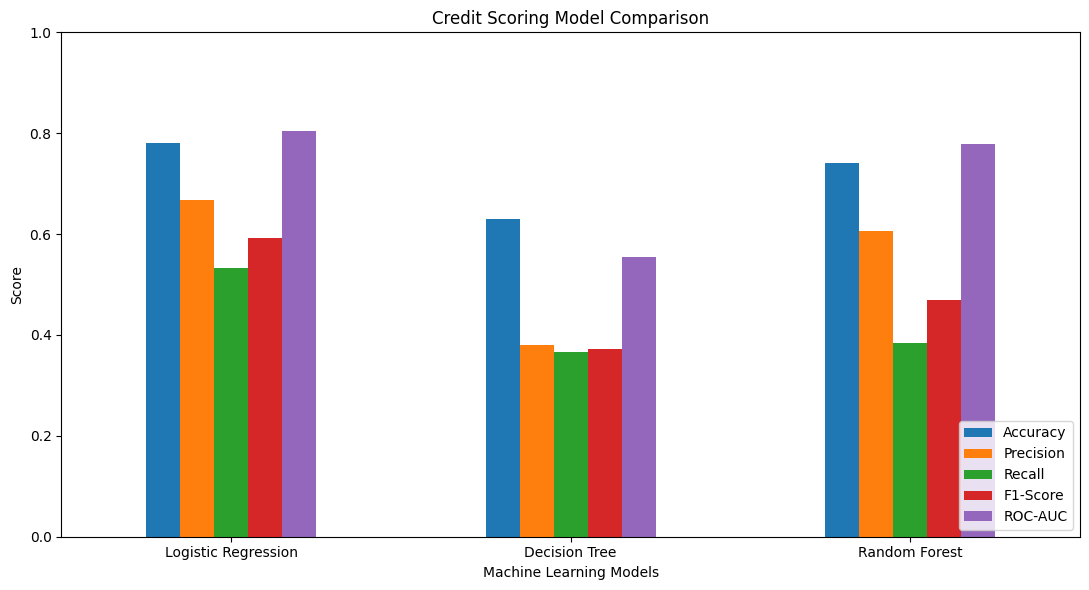

In [18]:

import matplotlib.pyplot as plt

results_df.set_index("Model").plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Credit Scoring Model Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


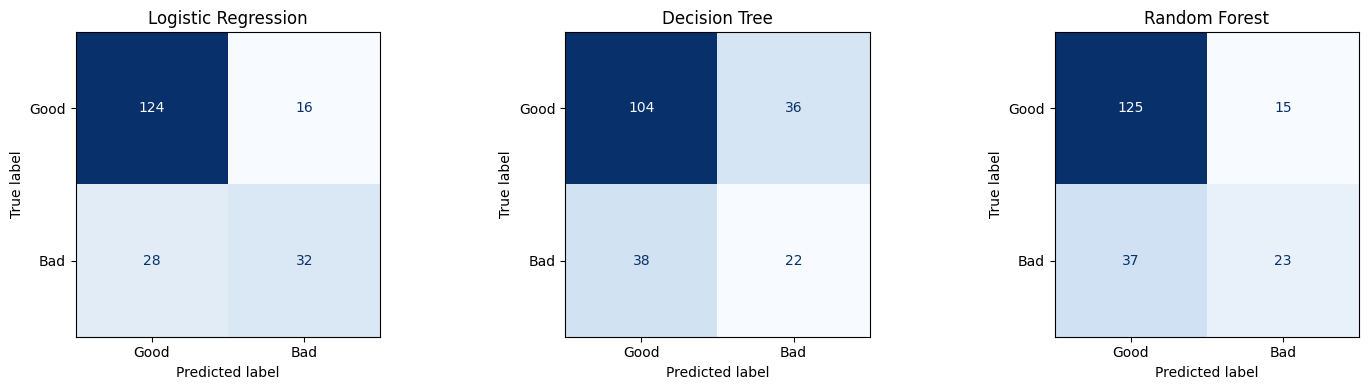

In [19]:

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(
    axes, trained_models.items()
):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=["Good", "Bad"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()


In [20]:

import joblib

best_model = trained_models["Logistic Regression"]

# Save both preprocessing and model
joblib.dump({
    "preprocessor": preprocessor,
    "model": best_model,
    "feature_columns": X.columns.tolist()
}, "credit_scoring_model.pkl")

print("Model saved successfully!")


Model saved successfully!


In [21]:

import joblib

# Load the saved model
saved = joblib.load("credit_scoring_model.pkl")

# Take one applicant from the original dataset
applicant = X.iloc[[0]]

# Apply the saved preprocessing
applicant_processed = saved["preprocessor"].transform(
    applicant[saved["feature_columns"]]
)

# Predict credit risk
prediction = saved["model"].predict(applicant_processed)[0]

# Calculate probability of bad credit risk
probability = saved["model"].predict_proba(
    applicant_processed
)[0][1]

print("Predicted Credit Risk:",
      "Bad" if prediction == 1 else "Good")

print(f"Estimated Bad Risk Probability: {probability:.2%}")


Predicted Credit Risk: Good
Estimated Bad Risk Probability: 3.77%


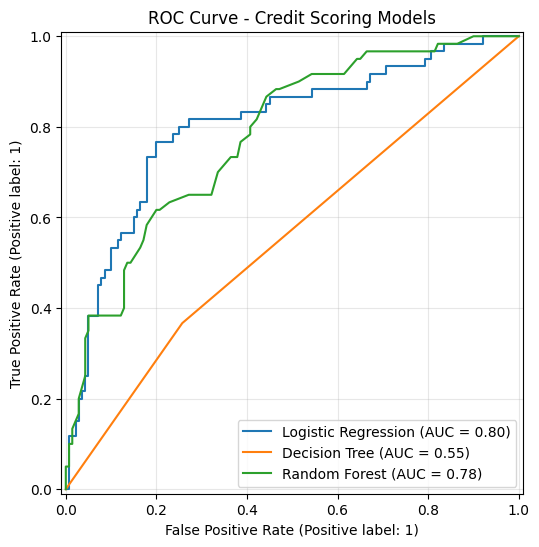

In [22]:

from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
ax = plt.gca()

for name, model in trained_models.items():
    RocCurveDisplay.from_estimator(
        model, X_test, y_test,
        name=name, ax=ax
    )

plt.title("ROC Curve - Credit Scoring Models")
plt.grid(alpha=0.3)
plt.show()
